# harley1991

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_Tk(T_leaf):
    return T_leaf + 273.15

def _derived_Kc(R_gas, c_Kc, dHa_Kc, Tk):
    return 10 * np.exp((c_Kc) - ((dHa_Kc) / (R_gas * Tk)))

def _derived_Ko(R_gas, c_Ko, dHa_Ko, Tk):
    return 10 * np.exp((c_Ko) - ((dHa_Ko) / (R_gas * Tk)))

def _derived_tau(R_gas, c_tau, dHa_tau, Tk):
    return np.exp((c_tau) - ((dHa_tau) / (R_gas * Tk)))

def _derived_Phi(Ci, O, tau):
    return (1000 * O) / (tau * Ci)

def _derived_Gamma_star(O, tau):
    return (500 * O) / (tau)

def _derived_J(PPFD, R, alpha):
    return (alpha * PPFD) / (np.pow(1 + ((alpha * PPFD) / (4 * R)) ** (2), 1 / 2))

def _derived_Wc(Ci, O, Vcmax, Kc, Ko):
    return (Vcmax * Ci) / (Ci + Kc * (1 + (O) / (Ko)))

def _derived_Wj(Phi, J):
    return (J) / (4 * (1 + Phi))

def _derived_Wp(T, f_gly, Phi):
    return (3 * T) / (max((1) - (2 * ((1) - (f_gly)) * Phi), 1e-12))

def _derived_Ac(Rd, Phi, Wc):
    return (((1) - (0.5 * Phi)) * Wc) - (Rd)

def _derived_Aj(Rd, Phi, Wj):
    return (((1) - (0.5 * Phi)) * Wj) - (Rd)

def _derived_Ap(Rd, Phi, Wp):
    return (((1) - (0.5 * Phi)) * Wp) - (Rd)

def _derived_A(Rd, Phi, Wc, Wj, Wp):
    return (((1) - (0.5 * Phi)) * min(Wc, Wj, Wp)) - (Rd)

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("Ci", 400, unit=su.bar*su.micro, display_name="Ci", tex_name="C", slider=Slider(min="20", max="1000", step="5"))
    m.add_parameter("O", 180, unit=su.bar*su.milli, display_name="O", tex_name="O", slider=Slider(min="10", max="500", step="5"))
    m.add_parameter("T_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="T_leaf", tex_name="T_{leaf}", slider=Slider(min="15", max="40", step="0.5"))
    m.add_parameter("PPFD", 1500, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="PPFD", tex_name="I", slider=Slider(min="0", max="2000", step="10"))
    m.add_parameter("Vcmax", 120.9, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{c,max}", slider=Slider(min="20", max="200", step="0.5"))
    m.add_parameter("R", 49.6, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="R", tex_name="R", slider=Slider(min="10", max="100", step="0.5"))
    m.add_parameter("T", 9.62, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="T", tex_name="T", slider=Slider(min="2", max="20", step="0.1"))
    m.add_parameter("Rd", 0, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d", slider=Slider(min="0", max="5", step="0.05"))
    m.add_parameter("f_gly", 0.5, unit=None, display_name="f_gly", tex_name="f_{gly}", slider=Slider(min="0", max="0.75", step="0.05"))
    m.add_parameter("alpha", 0.24, unit=None, tex_name="\\alpha")
    m.add_parameter("R_gas", 0.00831, unit=su.joule*su.kilo/(su.kelvin*su.mol), tex_name="R_{gas}")
    m.add_parameter("c_Kc", 35.79, unit=None, tex_name="c_{K_c}")
    m.add_parameter("dHa_Kc", 80.47, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_c}")
    m.add_parameter("c_Ko", 9.59, unit=None, tex_name="c_{K_o}")
    m.add_parameter("dHa_Ko", 14.51, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_o}")
    m.add_parameter("c_tau", -3.9489, unit=None, tex_name="c_{\\tau}")
    m.add_parameter("dHa_tau", -28.99, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,\\tau}")
    m.add_derived("Tk", _derived_Tk, args=["T_leaf"], unit=su.kelvin, tex_name="T_k")
    m.add_derived("Kc", _derived_Kc, args=["R_gas", "c_Kc", "dHa_Kc", "Tk"], unit=su.bar*su.micro, display_name="Kc", tex_name="K_c")
    m.add_derived("Ko", _derived_Ko, args=["R_gas", "c_Ko", "dHa_Ko", "Tk"], unit=su.bar*su.milli, display_name="Ko", tex_name="K_o")
    m.add_derived("tau", _derived_tau, args=["R_gas", "c_tau", "dHa_tau", "Tk"], unit=None, display_name="tau", tex_name="\\tau")
    m.add_derived("Phi", _derived_Phi, args=["Ci", "O", "tau"], unit=None, display_name="Phi", tex_name="\\Phi")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["O", "tau"], unit=su.bar*su.micro, display_name="Gamma_star", tex_name="\\Gamma^*")
    m.add_derived("J", _derived_J, args=["PPFD", "R", "alpha"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J")
    m.add_derived("Wc", _derived_Wc, args=["Ci", "O", "Vcmax", "Kc", "Ko"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wc", tex_name="W_c")
    m.add_derived("Wj", _derived_Wj, args=["Phi", "J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wj", tex_name="W_j")
    m.add_derived("Wp", _derived_Wp, args=["T", "f_gly", "Phi"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wp", tex_name="W_p")
    m.add_derived("Ac", _derived_Ac, args=["Rd", "Phi", "Wc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac", tex_name="A_c")
    m.add_derived("Aj", _derived_Aj, args=["Rd", "Phi", "Wj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj", tex_name="A_j")
    m.add_derived("Ap", _derived_Ap, args=["Rd", "Phi", "Wp"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ap", tex_name="A_p")
    m.add_derived("A", _derived_A, args=["Rd", "Phi", "Wc", "Wj", "Wp"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A", tex_name="A")
    return m


## Figure 1: fits to cotton A–Ci curves (29 °C)

In [3]:
tables = {}

# Scan a_o20
to_scan = pd.DataFrame({"Ci": np.linspace(20, 800, 391), "T_leaf": 29, "Rd": 2.12, "Vcmax": 127.3, "R": 57.65, "T": 12.6, "f_gly": 0.75, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_o20"] = {
    "x": np.linspace(20, 800, 391),
    "A": frame["A"].to_numpy(),
}

# Scan a_o200
to_scan = pd.DataFrame({"Ci": np.linspace(20, 800, 391), "T_leaf": 29, "Rd": 2.12, "Vcmax": 127.3, "R": 57.65, "T": 12.6, "f_gly": 0.75, "PPFD": 1500, "O": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_o200"] = {
    "x": np.linspace(20, 800, 391),
    "A": frame["A"].to_numpy(),
}

# Scan b_o20
to_scan = pd.DataFrame({"Ci": np.linspace(20, 800, 391), "T_leaf": 29, "Rd": 2.12, "Vcmax": 127.3, "R": 56.7, "T": 12.04, "f_gly": 0, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["b_o20"] = {
    "x": np.linspace(20, 800, 391),
    "A": frame["A"].to_numpy(),
}

# Scan b_o200
to_scan = pd.DataFrame({"Ci": np.linspace(20, 800, 391), "T_leaf": 29, "Rd": 2.12, "Vcmax": 127.3, "R": 56.7, "T": 12.04, "f_gly": 0, "PPFD": 1500, "O": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["b_o200"] = {
    "x": np.linspace(20, 800, 391),
    "A": frame["A"].to_numpy(),
}

# Scan c_o20
to_scan = pd.DataFrame({"Ci": np.linspace(20, 800, 391), "T_leaf": 29, "Rd": 2.12, "Vcmax": 127.3, "R": 56.7, "T": 12.39, "f_gly": 0.5, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["c_o20"] = {
    "x": np.linspace(20, 800, 391),
    "A": frame["A"].to_numpy(),
}

# Scan c_o200
to_scan = pd.DataFrame({"Ci": np.linspace(20, 800, 391), "T_leaf": 29, "Rd": 2.12, "Vcmax": 127.3, "R": 56.7, "T": 12.39, "f_gly": 0.5, "PPFD": 1500, "O": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["c_o200"] = {
    "x": np.linspace(20, 800, 391),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/391 [00:00<?, ?it/s]

100%|██████████| 391/391 [00:00<00:00, 5562.02it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

100%|██████████| 391/391 [00:00<00:00, 5858.13it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

100%|██████████| 391/391 [00:00<00:00, 5679.36it/s]

... (2 outputs left out)

  0%|          | 0/391 [00:00<?, ?it/s]

100%|██████████| 391/391 [00:00<00:00, 5695.22it/s]

  0%|          | 0/391 [00:00<?, ?it/s]

100%|██████████| 391/391 [00:00<00:00, 5615.25it/s]

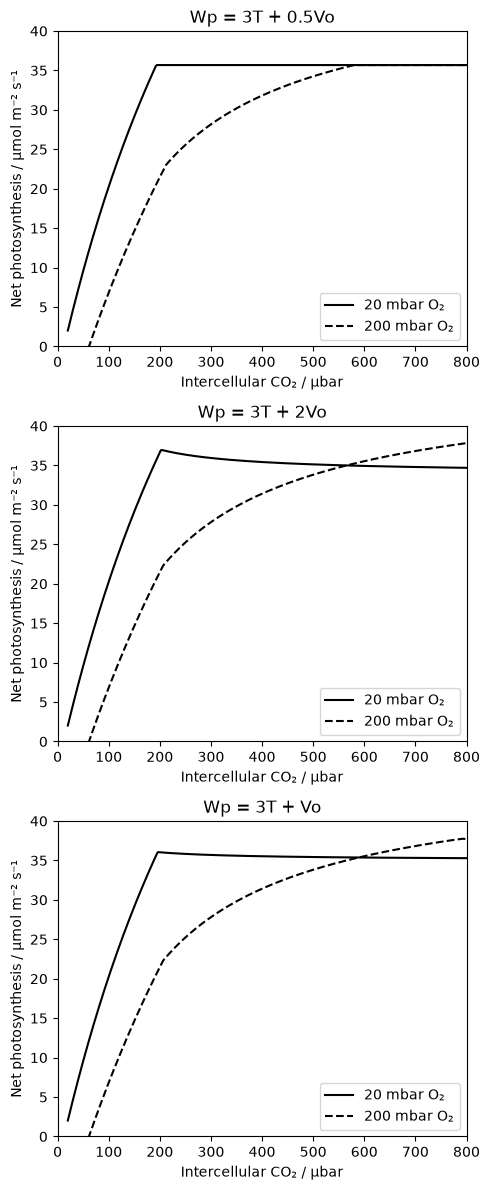

In [4]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(5, 12), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Wp = 3T + 0.5Vo")
ax0.plot(tables["a_o20"]["x"], tables["a_o20"]["A"], color="black", ls="-", label="20 mbar O₂")
ax0.plot(tables["a_o200"]["x"], tables["a_o200"]["A"], color="black", ls="--", label="200 mbar O₂")
ax0.set_xlabel("Intercellular CO₂ / µbar")
ax0.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 800)
ax0.set_ylim(0, 40)
ax0.legend()
ax1 = axs[1, 0]
ax1.set_title("Wp = 3T + 2Vo")
ax1.plot(tables["b_o20"]["x"], tables["b_o20"]["A"], color="black", ls="-", label="20 mbar O₂")
ax1.plot(tables["b_o200"]["x"], tables["b_o200"]["A"], color="black", ls="--", label="200 mbar O₂")
ax1.set_xlabel("Intercellular CO₂ / µbar")
ax1.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 800)
ax1.set_ylim(0, 40)
ax1.legend()
ax2 = axs[2, 0]
ax2.set_title("Wp = 3T + Vo")
ax2.plot(tables["c_o20"]["x"], tables["c_o20"]["A"], color="black", ls="-", label="20 mbar O₂")
ax2.plot(tables["c_o200"]["x"], tables["c_o200"]["A"], color="black", ls="--", label="200 mbar O₂")
ax2.set_xlabel("Intercellular CO₂ / µbar")
ax2.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax2.set_xlim(0, 800)
ax2.set_ylim(0, 40)
ax2.legend()
plt.tight_layout()
plt.show()

## Figure 2: fits to soybean A–Ci curves (25 °C)

In [5]:
tables = {}

# Scan a_o20
to_scan = pd.DataFrame({"Ci": np.linspace(20, 900, 441), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 49.6, "T": 10.01, "f_gly": 0.75, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_o20"] = {
    "x": np.linspace(20, 900, 441),
    "A": frame["A"].to_numpy(),
}

# Scan a_o180
to_scan = pd.DataFrame({"Ci": np.linspace(20, 900, 441), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 49.6, "T": 10.01, "f_gly": 0.75, "PPFD": 1500, "O": 180})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["a_o180"] = {
    "x": np.linspace(20, 900, 441),
    "A": frame["A"].to_numpy(),
}

# Scan b_o20
to_scan = pd.DataFrame({"Ci": np.linspace(20, 900, 441), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 49, "T": 9.06, "f_gly": 0, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["b_o20"] = {
    "x": np.linspace(20, 900, 441),
    "A": frame["A"].to_numpy(),
}

# Scan b_o180
to_scan = pd.DataFrame({"Ci": np.linspace(20, 900, 441), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 49, "T": 9.06, "f_gly": 0, "PPFD": 1500, "O": 180})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["b_o180"] = {
    "x": np.linspace(20, 900, 441),
    "A": frame["A"].to_numpy(),
}

# Scan c_o20
to_scan = pd.DataFrame({"Ci": np.linspace(20, 900, 441), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 49.6, "T": 9.62, "f_gly": 0.5, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["c_o20"] = {
    "x": np.linspace(20, 900, 441),
    "A": frame["A"].to_numpy(),
}

# Scan c_o180
to_scan = pd.DataFrame({"Ci": np.linspace(20, 900, 441), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 49.6, "T": 9.62, "f_gly": 0.5, "PPFD": 1500, "O": 180})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["c_o180"] = {
    "x": np.linspace(20, 900, 441),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/441 [00:00<?, ?it/s]

100%|██████████| 441/441 [00:00<00:00, 5784.22it/s]

  0%|          | 0/441 [00:00<?, ?it/s]

100%|██████████| 441/441 [00:00<00:00, 5796.18it/s]

  0%|          | 0/441 [00:00<?, ?it/s]

100%|██████████| 441/441 [00:00<00:00, 5817.47it/s]

... (2 outputs left out)

  0%|          | 0/441 [00:00<?, ?it/s]

100%|██████████| 441/441 [00:00<00:00, 5604.71it/s]

  0%|          | 0/441 [00:00<?, ?it/s]

100%|██████████| 441/441 [00:00<00:00, 5556.49it/s]

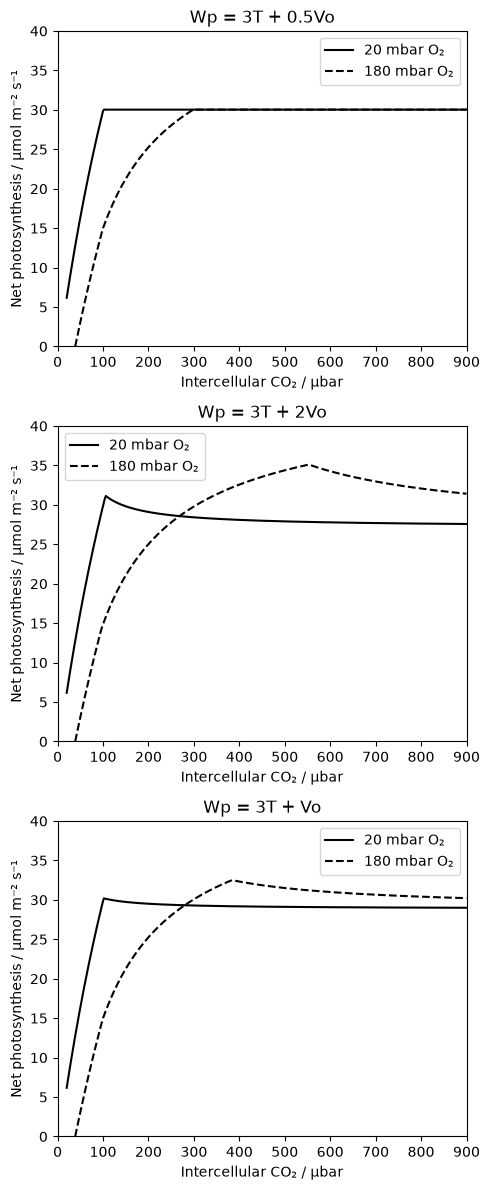

In [6]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(5, 12), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Wp = 3T + 0.5Vo")
ax0.plot(tables["a_o20"]["x"], tables["a_o20"]["A"], color="black", ls="-", label="20 mbar O₂")
ax0.plot(tables["a_o180"]["x"], tables["a_o180"]["A"], color="black", ls="--", label="180 mbar O₂")
ax0.set_xlabel("Intercellular CO₂ / µbar")
ax0.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 900)
ax0.set_ylim(0, 40)
ax0.legend()
ax1 = axs[1, 0]
ax1.set_title("Wp = 3T + 2Vo")
ax1.plot(tables["b_o20"]["x"], tables["b_o20"]["A"], color="black", ls="-", label="20 mbar O₂")
ax1.plot(tables["b_o180"]["x"], tables["b_o180"]["A"], color="black", ls="--", label="180 mbar O₂")
ax1.set_xlabel("Intercellular CO₂ / µbar")
ax1.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 900)
ax1.set_ylim(0, 40)
ax1.legend()
ax2 = axs[2, 0]
ax2.set_title("Wp = 3T + Vo")
ax2.plot(tables["c_o20"]["x"], tables["c_o20"]["A"], color="black", ls="-", label="20 mbar O₂")
ax2.plot(tables["c_o180"]["x"], tables["c_o180"]["A"], color="black", ls="--", label="180 mbar O₂")
ax2.set_xlabel("Intercellular CO₂ / µbar")
ax2.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax2.set_xlim(0, 900)
ax2.set_ylim(0, 40)
ax2.legend()
plt.tight_layout()
plt.show()

## Figure 3: A–Ci curves at four irradiances (210 mbar O₂)

In [7]:
tables = {}

# Scan PPFD1500
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 1500, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["PPFD1500"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

# Scan PPFD1200
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 1200, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["PPFD1200"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

# Scan PPFD900
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 900, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["PPFD900"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

# Scan PPFD600
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 600, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["PPFD600"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5556.46it/s]

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5099.96it/s]

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5604.62it/s]

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5661.77it/s]

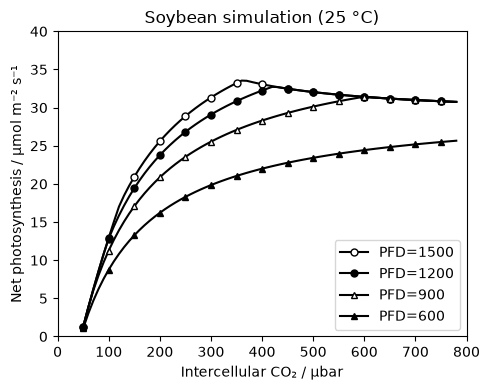

In [8]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Soybean simulation (25 °C)")
ax0.plot(tables["PPFD1500"]["x"], tables["PPFD1500"]["A"], color="black", marker="o", markersize=5, markerfacecolor="white", markeredgecolor="black", markevery=5, label="PFD=1500")
ax0.plot(tables["PPFD1200"]["x"], tables["PPFD1200"]["A"], color="black", marker="o", markersize=5, markerfacecolor="black", markeredgecolor="black", markevery=5, label="PFD=1200")
ax0.plot(tables["PPFD900"]["x"], tables["PPFD900"]["A"], color="black", marker="^", markersize=5, markerfacecolor="white", markeredgecolor="black", markevery=5, label="PFD=900")
ax0.plot(tables["PPFD600"]["x"], tables["PPFD600"]["A"], color="black", marker="^", markersize=5, markerfacecolor="black", markeredgecolor="black", markevery=5, label="PFD=600")
ax0.set_xlabel("Intercellular CO₂ / µbar")
ax0.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 800)
ax0.set_ylim(0, 40)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 4: A–Ci curves at 20, 200 and 400 mbar O₂

In [9]:
tables = {}

# Scan O20
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 1500, "O": 20})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O20"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

# Scan O200
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 1500, "O": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O200"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

# Scan O400
to_scan = pd.DataFrame({"Ci": np.linspace(50, 780, 74), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9.62, "f_gly": 0.5, "PPFD": 1500, "O": 400})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["O400"] = {
    "x": np.linspace(50, 780, 74),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5516.96it/s]

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5688.44it/s]

  0%|          | 0/74 [00:00<?, ?it/s]

100%|██████████| 74/74 [00:00<00:00, 5512.55it/s]

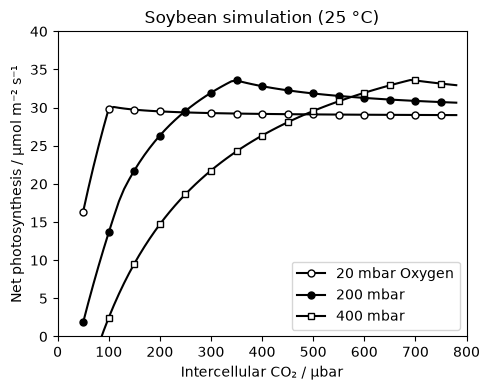

In [10]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Soybean simulation (25 °C)")
ax0.plot(tables["O20"]["x"], tables["O20"]["A"], color="black", marker="o", markersize=5, markerfacecolor="white", markeredgecolor="black", markevery=5, label="20 mbar Oxygen")
ax0.plot(tables["O200"]["x"], tables["O200"]["A"], color="black", marker="o", markersize=5, markerfacecolor="black", markeredgecolor="black", markevery=5, label="200 mbar")
ax0.plot(tables["O400"]["x"], tables["O400"]["A"], color="black", marker="s", markersize=5, markerfacecolor="white", markeredgecolor="black", markevery=5, label="400 mbar")
ax0.set_xlabel("Intercellular CO₂ / µbar")
ax0.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 800)
ax0.set_ylim(0, 40)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 5: decreasing triose phosphate utilisation (210 mbar O₂)

In [11]:
tables = {}

# Scan T12
to_scan = pd.DataFrame({"Ci": np.linspace(50, 550, 51), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 12, "f_gly": 0.5, "PPFD": 1500, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T12"] = {
    "x": np.linspace(50, 550, 51),
    "A": frame["A"].to_numpy(),
}

# Scan T9
to_scan = pd.DataFrame({"Ci": np.linspace(50, 550, 51), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 9, "f_gly": 0.5, "PPFD": 1500, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T9"] = {
    "x": np.linspace(50, 550, 51),
    "A": frame["A"].to_numpy(),
}

# Scan T6
to_scan = pd.DataFrame({"Ci": np.linspace(50, 550, 51), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 6, "f_gly": 0.5, "PPFD": 1500, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T6"] = {
    "x": np.linspace(50, 550, 51),
    "A": frame["A"].to_numpy(),
}

# Scan T3
to_scan = pd.DataFrame({"Ci": np.linspace(50, 550, 51), "T_leaf": 25, "Rd": 0, "Vcmax": 120.9, "R": 56.7, "T": 3, "f_gly": 0.5, "PPFD": 1500, "O": 210})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["A"]].isna().any(axis=None)
tables["T3"] = {
    "x": np.linspace(50, 550, 51),
    "A": frame["A"].to_numpy(),
}

  0%|          | 0/51 [00:00<?, ?it/s]

100%|██████████| 51/51 [00:00<00:00, 5579.13it/s]

  0%|          | 0/51 [00:00<?, ?it/s]

100%|██████████| 51/51 [00:00<00:00, 5347.20it/s]

  0%|          | 0/51 [00:00<?, ?it/s]

100%|██████████| 51/51 [00:00<00:00, 5491.05it/s]

  0%|          | 0/51 [00:00<?, ?it/s]

100%|██████████| 51/51 [00:00<00:00, 5525.52it/s]

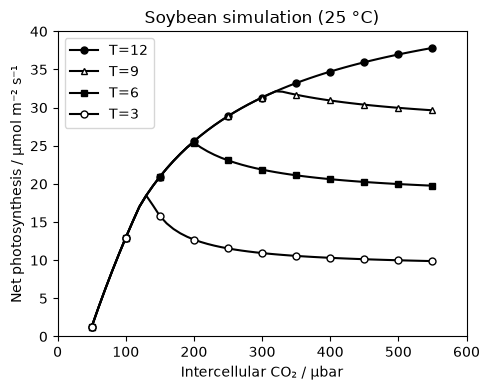

In [12]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Soybean simulation (25 °C)")
ax0.plot(tables["T12"]["x"], tables["T12"]["A"], color="black", marker="o", markersize=5, markerfacecolor="black", markeredgecolor="black", markevery=5, label="T=12")
ax0.plot(tables["T9"]["x"], tables["T9"]["A"], color="black", marker="^", markersize=5, markerfacecolor="white", markeredgecolor="black", markevery=5, label="T=9")
ax0.plot(tables["T6"]["x"], tables["T6"]["A"], color="black", marker="s", markersize=5, markerfacecolor="black", markeredgecolor="black", markevery=5, label="T=6")
ax0.plot(tables["T3"]["x"], tables["T3"]["A"], color="black", marker="o", markersize=5, markerfacecolor="white", markeredgecolor="black", markevery=5, label="T=3")
ax0.set_xlabel("Intercellular CO₂ / µbar")
ax0.set_ylabel("Net photosynthesis / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 600)
ax0.set_ylim(0, 40)
ax0.legend()
plt.tight_layout()
plt.show()